# ThreatGraph demo

This notebook walks through the project with real queries against the loaded graph:

1. the schema and what is in the graph
2. the seven questions the project answers
3. graph algorithms (GDS): centrality, communities, group similarity
4. the mitigation plan
5. link prediction, and why nothing is stored
6. the agent, including a guardrail rejecting bad LLM output

It is committed with its outputs, so it reads without running. To run it yourself: `make docker-run`,
`make download`, `make ingest`, `make predict`, and set `GROQ_API_KEY` in `.env` for the agent part.
Every answer below comes from the same service functions the API endpoints use.

In [1]:
import json
import logging
from pathlib import Path

import matplotlib.pyplot as plt
from IPython.display import Image, display

from app.database.connection import get_driver
from app.services import analytics, cves, groups, products, techniques

driver = get_driver()
# The guardrails read Neo4j's "unknown label" notices themselves; don't also print them as warnings.
logging.getLogger("neo4j.notifications").setLevel(logging.ERROR)


def q(cypher, **params):
    """Run a read query and return its rows as dicts."""
    records, _, _ = driver.execute_query(cypher, params)
    return [record.data() for record in records]


def show(rows, columns=None, limit=10):
    """Print rows as a small text table."""
    rows = list(rows)[:limit]
    if not rows:
        print("(no rows)")
        return
    columns = columns or list(rows[0])
    widths = [max(len(str(c)), *(len(str(r.get(c, ""))[:60]) for r in rows)) for c in columns]
    print("  ".join(str(c).ljust(w) for c, w in zip(columns, widths)))
    for r in rows:
        print("  ".join(str(r.get(c, ""))[:60].ljust(w) for c, w in zip(columns, widths)))

## 1. The graph

The schema (decisions D1–D19 in `docs/modeling_rationale.md`). ATT&CK gives groups, techniques,
tactics, mitigations and software; KEV and NVD give the exploited CVEs, their weaknesses (CWE) and the
products they affect (CPE); the CTID mappings are the bridge between a CVE and ATT&CK techniques.

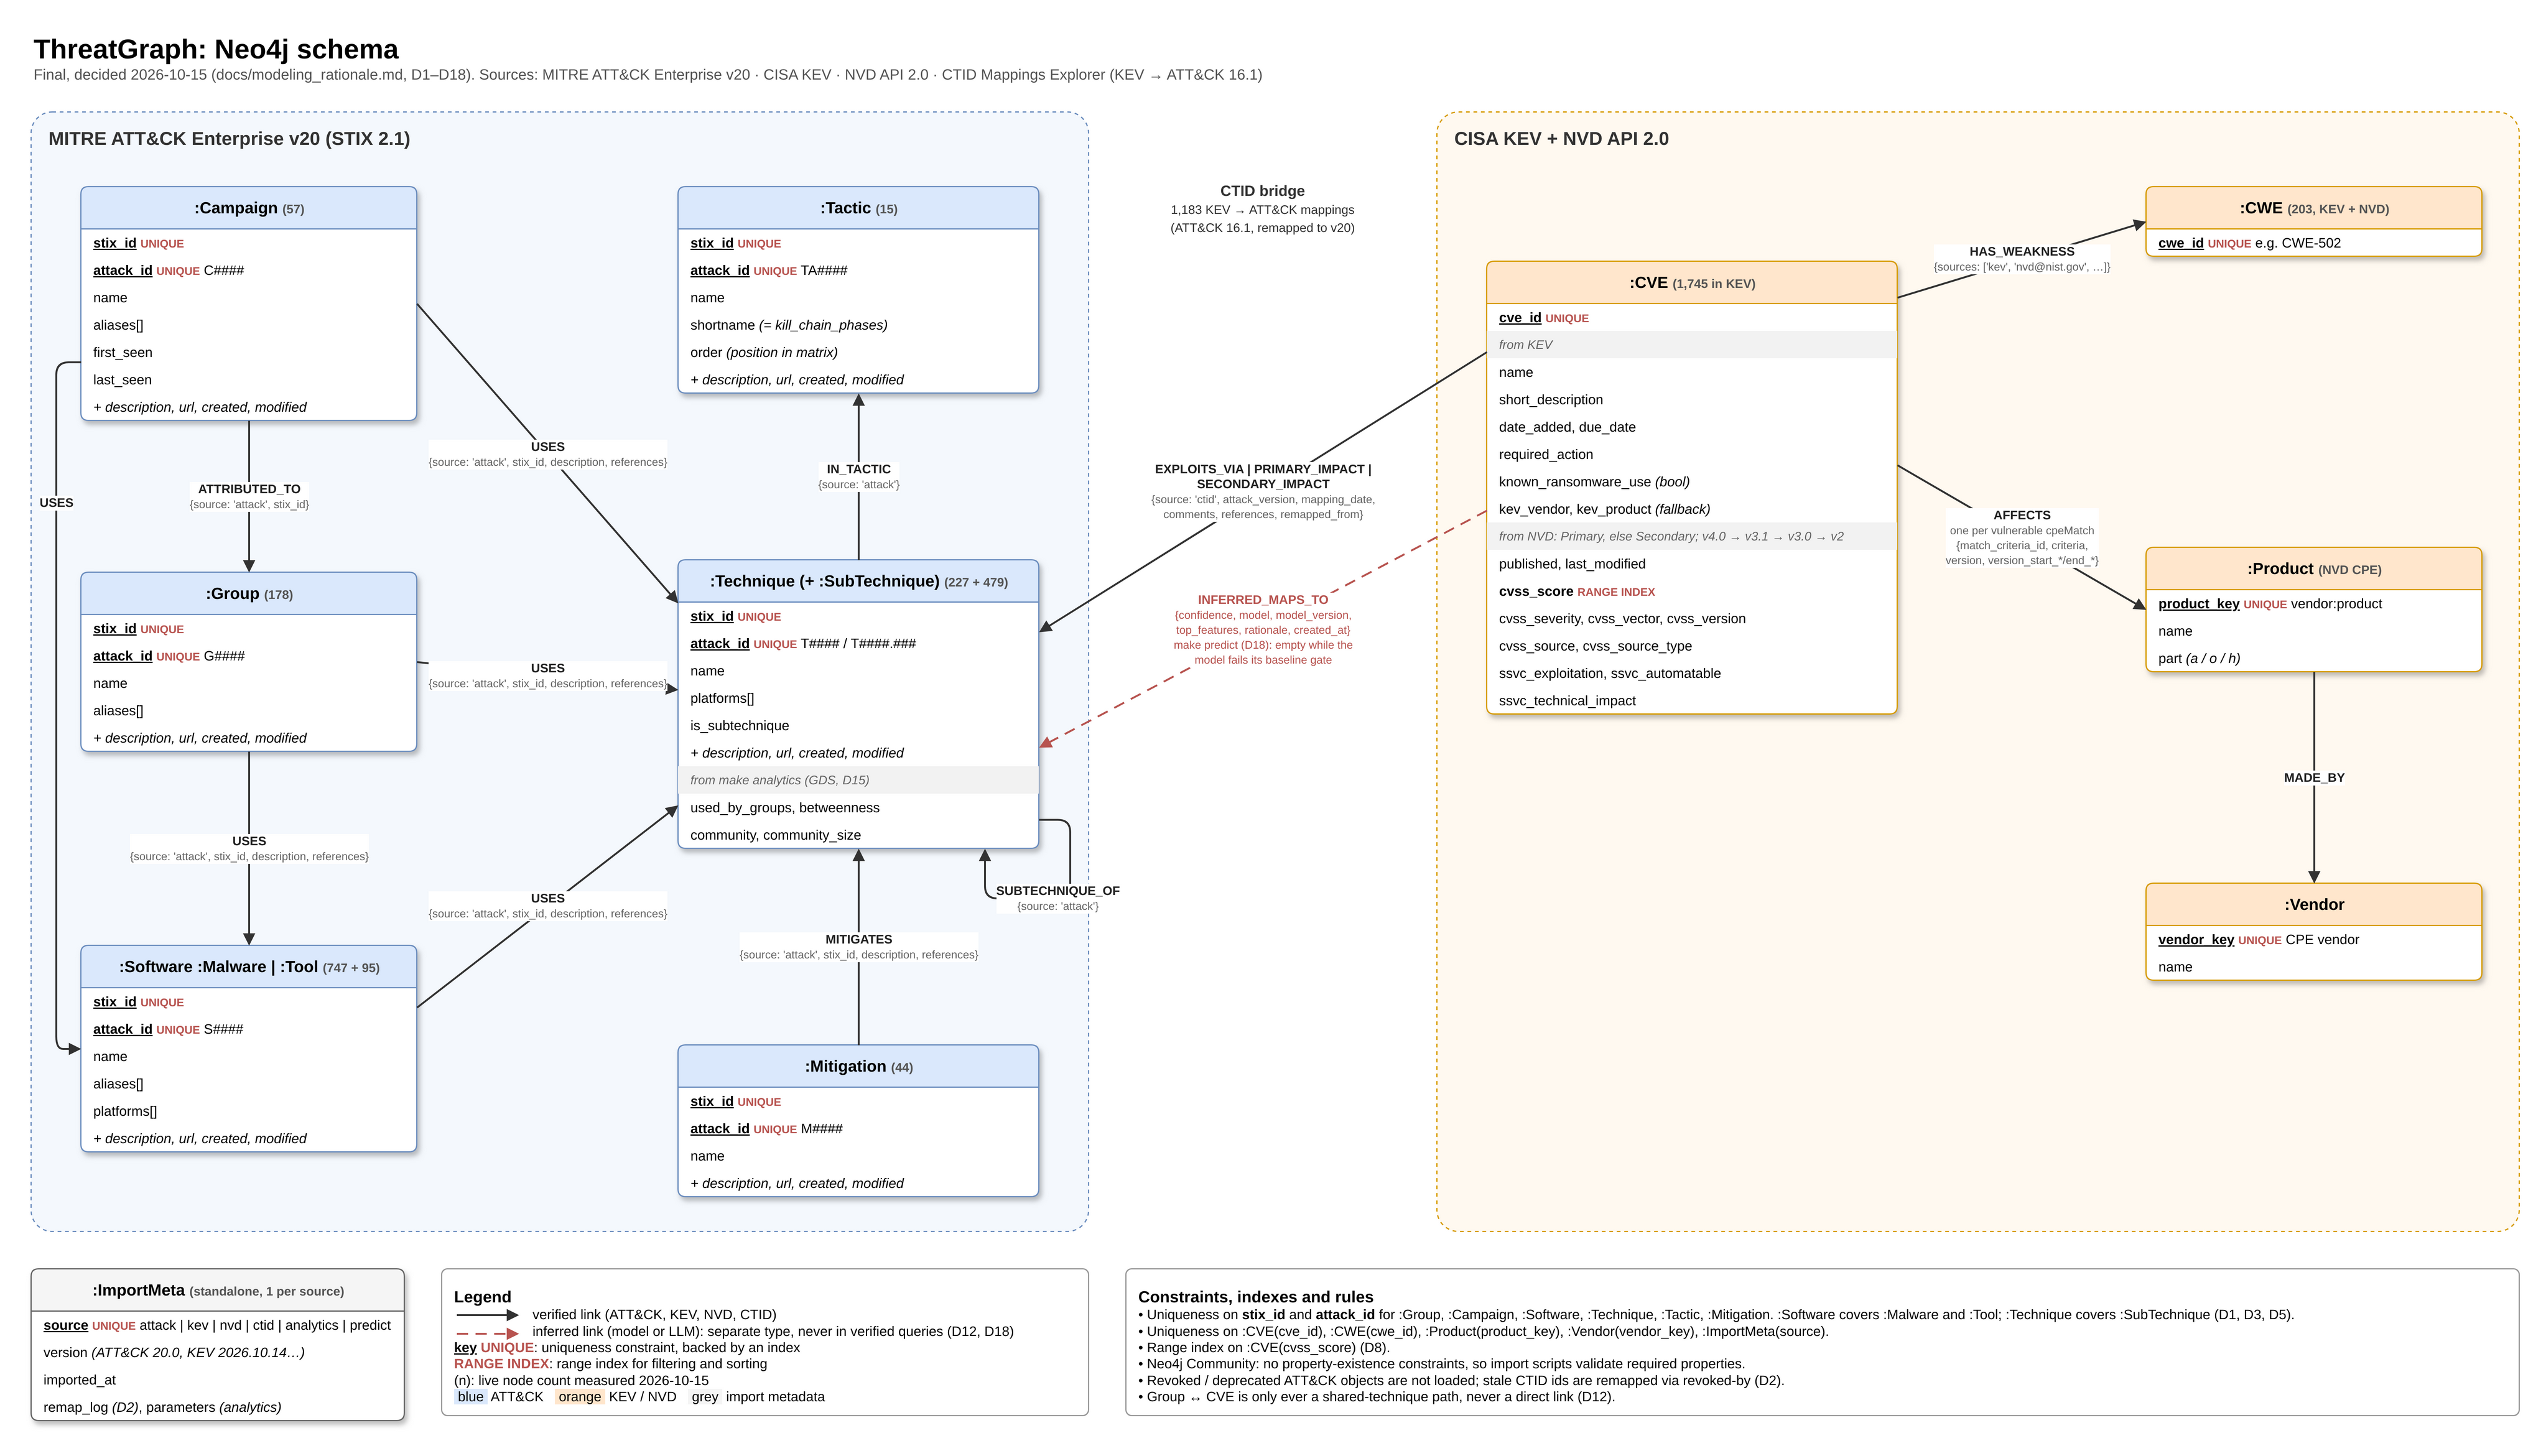

In [2]:
display(Image("docs/schema.png", width=900))

7,782 nodes, 60,061 relationships


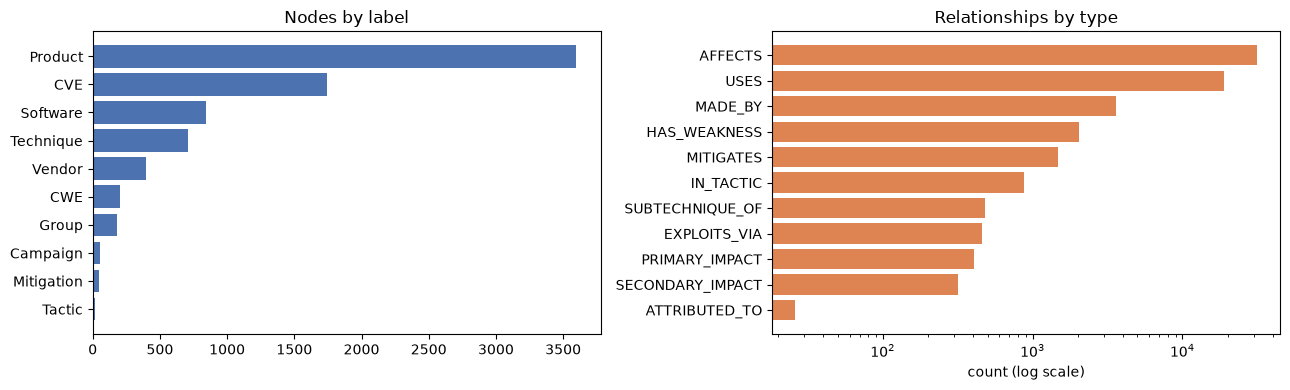

In [3]:
nodes = q("MATCH (n) WHERE NOT n:ImportMeta RETURN labels(n)[0] AS label, count(*) AS count ORDER BY count DESC")
rels = q("MATCH ()-[r]->() RETURN type(r) AS type, count(*) AS count ORDER BY count DESC")
print(f"{sum(r['count'] for r in nodes):,} nodes, {sum(r['count'] for r in rels):,} relationships")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].barh([r["label"] for r in nodes][::-1], [r["count"] for r in nodes][::-1], color="#4c72b0")
axes[0].set_title("Nodes by label")
axes[1].barh([r["type"] for r in rels][::-1], [r["count"] for r in rels][::-1], color="#dd8452")
axes[1].set_title("Relationships by type")
axes[1].set_xscale("log")
axes[1].set_xlabel("count (log scale)")
plt.tight_layout()
plt.show()

Where each source came from, as recorded at import time (`:ImportMeta`, D2):

In [4]:
show(q("MATCH (m:ImportMeta) RETURN m.source AS source, m.version AS version, "
       "toString(date(m.imported_at)) AS imported ORDER BY source"))

source     version                   imported  
analytics  2.13.14                   2026-10-16
attack     20.0                      2026-10-16
ctid       16.1                      2026-10-16
kev        2026.10.14                2026-10-16
nvd        2026-10-15                2026-10-16
predict    rf-2026-10-16-17d19efd7f  2026-10-16


## 2. The seven questions

### Q1. Which techniques does a group use, under which tactics, and what mitigates them?

APT29 (G0016). The query starts from one group and only walks its own relationships, so its cost
depends on that group's degree, not on the size of the graph.

APT29 uses 66 techniques


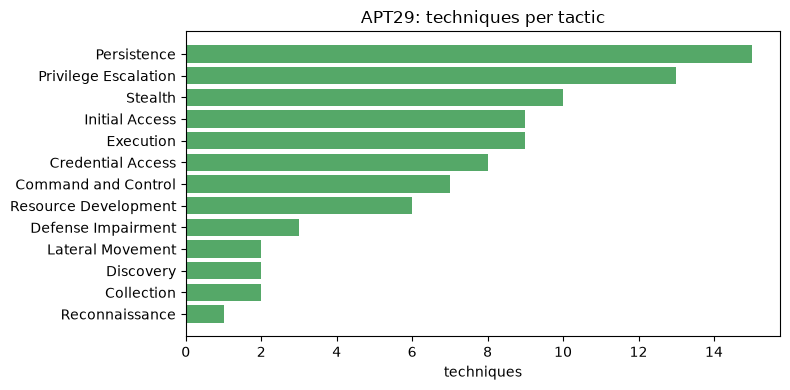

technique  name                           mitigations
T1003.002  Security Account Manager       4          
T1003.004  LSA Secrets                    3          
T1005      Data from Local System         1          
T1016.001  Internet Connection Discovery  0          
T1021.007  Cloud Services                 2          


In [5]:
apt29 = groups.group_techniques(driver, "G0016")
print(apt29.group.name, "uses", apt29.technique_count, "techniques")

per_tactic = {}
for t in apt29.techniques:
    for tactic in t.tactics:
        per_tactic[tactic] = per_tactic.get(tactic, 0) + 1
ordered = sorted(per_tactic.items(), key=lambda kv: kv[1])
plt.figure(figsize=(8, 4))
plt.barh([k for k, _ in ordered], [v for _, v in ordered], color="#55a868")
plt.title("APT29: techniques per tactic")
plt.xlabel("techniques")
plt.tight_layout()
plt.show()

show([{"technique": t.attack_id, "name": t.name, "mitigations": len(t.mitigations)} for t in apt29.techniques], limit=5)

### Q2. Which exploited CVEs map to a technique, and which have known ransomware use?

T1190 (Exploit Public-Facing Application), ransomware only. Sub-techniques are included.

In [6]:
t1190 = techniques.technique_cves(driver, "T1190", ransomware=True)
print(t1190.cve_count, "KEV CVEs with known ransomware use map to", t1190.technique.name)
show([c.model_dump() for c in t1190.cves], ["cve_id", "cvss_score", "date_added", "name"], limit=5)

69 KEV CVEs with known ransomware use map to Exploit Public-Facing Application
cve_id          cvss_score  date_added  name                                                        
CVE-2021-22205  10.0        2021-11-03  GitLab Community and Enterprise Editions Remote Code Executi
CVE-2021-22893  10.0        2021-11-03  Ivanti Pulse Connect Secure Use-After-Free Vulnerability    
CVE-2021-34473  10.0        2021-11-03  Microsoft Exchange Server Remote Code Execution Vulnerabilit
CVE-2021-44228  10.0        2021-12-10  Apache Log4j2 Remote Code Execution Vulnerability           
CVE-2023-48365  9.9         2025-01-13  Qlik Sense HTTP Tunneling Vulnerability                     


### Q3. Which groups are associated with a CVE?

Log4Shell. Groups are linked only through a technique the CVE enables, so this is an association,
never proof that the group exploited the CVE (D12). The note travels with every such answer.

In [7]:
log4shell = cves.cve_groups(driver, "CVE-2021-44228", limit=5)
print("techniques:", [t.attack_id for t in log4shell.techniques])
print("groups sharing one of them:", log4shell.group_count)
show([g.model_dump() for g in log4shell.groups])
print()
print(log4shell.note)

techniques: ['T1190', 'T1486', 'T1496', 'T1505.003', 'T1608.001']
groups sharing one of them: 80
attack_id  name           shared_techniques                           
G1043      BlackByte      ['T1190', 'T1486', 'T1608.001', 'T1505.003']
G0034      Sandworm Team  ['T1190', 'T1486', 'T1608.001', 'T1505.003']
G0082      APT38          ['T1486', 'T1608.001', 'T1505.003']         
G0046      FIN7           ['T1190', 'T1486', 'T1608.001']             
G0094      Kimsuky        ['T1190', 'T1608.001', 'T1505.003']         

Groups are listed because they use a technique this vulnerability enables (CTID mapping). This is an association through a shared technique, not evidence that the group exploited the vulnerability.


### Q4. Which vendors and products have the most exploited CVEs, and which weaknesses?

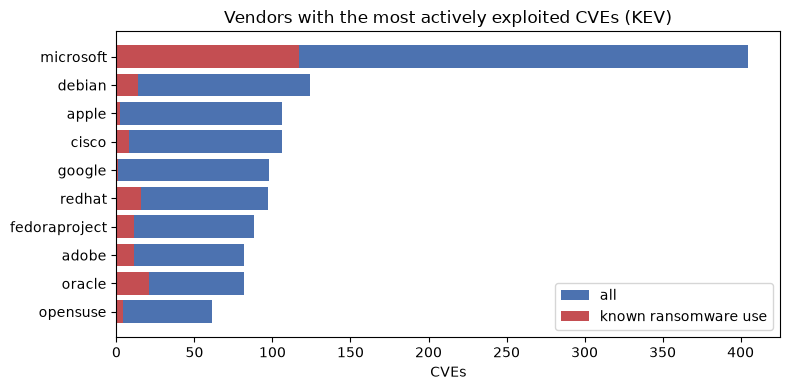

vendor     cves  top weaknesses                   
microsoft  405   ['CWE-787', 'CWE-119', 'CWE-416']
debian     124   ['CWE-787', 'CWE-416', 'CWE-843']
apple      106   ['CWE-787', 'CWE-20', 'CWE-416'] 
cisco      106   ['CWE-20', 'CWE-119', 'CWE-399'] 
google     98    ['CWE-787', 'CWE-843', 'CWE-416']


In [8]:
vendors = products.top_vendors(driver, limit=10).vendors
plt.figure(figsize=(8, 4))
plt.barh([v.name for v in vendors][::-1], [v.exploited_cves for v in vendors][::-1], color="#4c72b0", label="all")
plt.barh([v.name for v in vendors][::-1], [v.ransomware_cves for v in vendors][::-1], color="#c44e52",
         label="known ransomware use")
plt.title("Vendors with the most actively exploited CVEs (KEV)")
plt.xlabel("CVEs")
plt.legend()
plt.tight_layout()
plt.show()
show([{"vendor": v.name, "cves": v.exploited_cves, "top weaknesses": [w.cwe_id for w in v.top_weaknesses]}
      for v in vendors], limit=5)

Debian is second because NVD's CPE data lists the Debian packages a CVE also affects. It is a real
effect of using CPE-level products (D10), not a bug.

### Q5 and Q6

The mitigation plan (Q5) and technique centrality (Q6) have their own sections below.

### Q7. What is a product's full exposure?

Fortinet FortiOS: its exploited CVEs, the techniques they enable, the groups using those techniques,
and the mitigations covering them.

In [9]:
fortios = products.product_exposure(driver, "fortinet:fortios", limit=5)
print(f"{fortios.cve_count} exploited CVEs, {fortios.mapped_cve_count} mapped to ATT&CK, "
      f"{fortios.technique_count} techniques")
show([t.model_dump() for t in fortios.techniques], ["attack_id", "name", "via_cves"], limit=5)
print()
show([g.model_dump() for g in fortios.groups], limit=5)
print()
show([m.model_dump() for m in fortios.mitigations], limit=5)

20 exploited CVEs, 10 mapped to ATT&CK, 20 techniques
attack_id  name                                  via_cves
T1190      Exploit Public-Facing Application     5       
T1574      Hijack Execution Flow                 4       
T1005      Data from Local System                1       
T1021      Remote Services                       1       
T1037      Boot or Logon Initialization Scripts  1       

attack_id  name               shared_techniques
G0096      APT41              8                
G0016      APT29              7                
G0049      OilRig             7                
G1045      Salt Typhoon       7                
G0027      Threat Group-3390  7                

attack_id  name                                     covers_techniques
M1018      User Account Management                  7                
M1026      Privileged Account Management            7                
M1032      Multi-factor Authentication              7                
M1022      Restrict File and

## 3. Graph algorithms (GDS)

### Centrality and communities (Q6)

`make analytics` computes these with GDS and stores them as properties (D15, D16):
- **degree:** how many groups use a technique;
- **betweenness**, on the technique co-usage graph: techniques that connect otherwise separate groups of techniques;
- **Louvain communities**, on a top-10 Jaccard similarity graph: techniques that tend to be used together.

Most used: ['T1105', 'T1204.002', 'T1059.001', 'T1588.002', 'T1566.001', 'T1059.003', 'T1036.005', 'T1082', 'T1547.001', 'T1071.001']
Best connectors: ['T1588.002', 'T1059.001', 'T1105', 'T1036.005', 'T1082', 'T1078', 'T1190', 'T1204.002', 'T1083', 'T1005']
Louvain: 317 communities, modularity 0.566


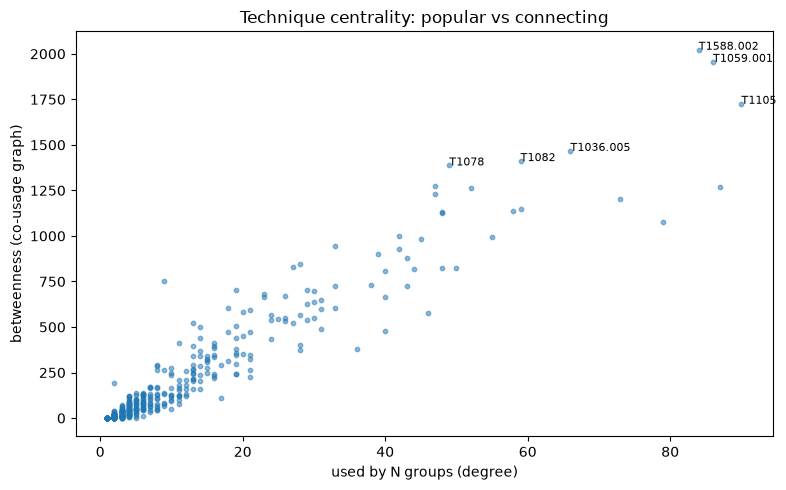

In [10]:
by_degree = analytics.central_techniques(driver, limit=10)
by_betweenness = analytics.central_techniques(driver, by="betweenness", limit=10)
print("Most used:", [t.attack_id for t in by_degree.techniques])
print("Best connectors:", [t.attack_id for t in by_betweenness.techniques])
print("Louvain:", by_degree.analytics.community_count, "communities, modularity",
      round(by_degree.analytics.modularity, 3))

points = q("MATCH (t:Technique) WHERE t.used_by_groups > 0 "
           "RETURN t.attack_id AS id, t.used_by_groups AS degree, t.betweenness AS betweenness")
plt.figure(figsize=(8, 5))
plt.scatter([p["degree"] for p in points], [p["betweenness"] for p in points], s=10, alpha=0.5)
for p in sorted(points, key=lambda p: -p["betweenness"])[:6]:
    plt.annotate(p["id"], (p["degree"], p["betweenness"]), fontsize=8)
plt.xlabel("used by N groups (degree)")
plt.ylabel("betweenness (co-usage graph)")
plt.title("Technique centrality: popular vs connecting")
plt.tight_layout()
plt.show()

In [11]:
for c in by_degree.communities:
    print(f"community {c.community} ({c.size} techniques): {', '.join(c.top_techniques)}")

community 418 (115 techniques): Ingress Tool Transfer, Malicious File, PowerShell, Tool, Spearphishing Attachment
community 56 (76 techniques): System Time Discovery, Local Accounts, Hidden Files and Directories, Compression, Remote Desktop Software
community 402 (56 techniques): Multi-hop Proxy, Gather Victim Org Information, Msiexec, Exfiltration Over Web Service, Credentials
community 226 (48 techniques): Dynamic-link Library Injection, Server, Internal Proxy, Peripheral Device Discovery, Indicator Removal from Tools
community 261 (41 techniques): Steal Web Session Cookie, Inhibit System Recovery, Password Managers, Permission Groups Discovery, Data from Cloud Storage
community 380 (31 techniques): Unix Shell, Disable or Modify System Firewall, Clear Command History, Private Keys, Rootkit


### Group similarity, computed live (D17)

GDS node similarity (Jaccard on the techniques each group uses) runs on request, on a projection
created and dropped for that one call.

In [12]:
similar = analytics.similar_groups(driver, "G0016", limit=5)
show([g.model_dump() for g in similar.similar])
left = q("CALL gds.graph.list() YIELD graphName RETURN count(*) AS n")[0]["n"]
print("projections left in the GDS catalog:", left)

attack_id  name               jaccard  shared_techniques  techniques_used
G0007      APT28              0.2231   29                 93             
G1018      TA2541             0.2051   16                 28             
G0064      APT33              0.1975   16                 31             
G0027      Threat Group-3390  0.1942   20                 57             
G0035      Dragonfly          0.1845   19                 56             
projections left in the GDS catalog: 0


## 4. Mitigation plan (Q5)

Which mitigations cover the most of what is actually exploited? Each technique reachable from a KEV
CVE is weighted by how many exploited CVEs map to it. The plan is a greedy weighted maximum
coverage: each pick adds the most uncovered weight. Greedy's first k picks are always within
1 - 1/e (about 63%) of the best possible k picks (D14).

rank  attack_id  name                                     gain  cumulative_pct
1     M1026      Privileged Account Management            497   42.2          
2     M1038      Execution Prevention                     175   57.1          
3     M1031      Network Intrusion Prevention             115   66.9          
4     M1051      Update Software                          72    73.0          
5     M1042      Disable or Remove Feature or Program     68    78.8          
6     M1057      Data Loss Prevention                     49    82.9          
7     M1018      User Account Management                  32    85.6          
8     M1040      Behavior Prevention on Endpoint          22    87.5          
9     M1037      Filter Network Traffic                   20    89.2          
10    M1056      Pre-compromise                           20    90.9          
11    M1022      Restrict File and Directory Permissions  15    92.2          
12    M1047      Audit                              

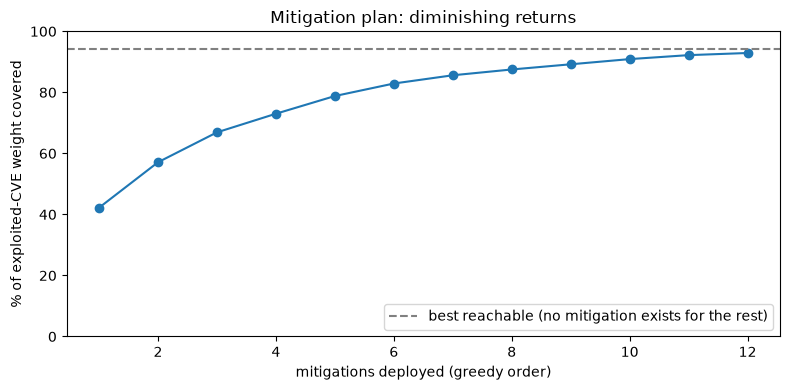

20 techniques (5.9% of the weight) have no ATT&CK mitigation at all:
T1496, T1202, T1082, T1070.004, T1083, T1497, T1056, T1018, T1033, T1140 ...


In [13]:
plan = analytics.mitigation_plan(driver, max_picks=12)
show([p.model_dump() for p in plan.picks], ["rank", "attack_id", "name", "gain", "cumulative_pct"], limit=12)

plt.figure(figsize=(8, 4))
plt.plot([p.rank for p in plan.picks], [p.cumulative_pct for p in plan.picks], marker="o")
plt.axhline(100 - plan.uncoverable.pct, color="grey", linestyle="--", label="best reachable (no mitigation exists for the rest)")
plt.xlabel("mitigations deployed (greedy order)")
plt.ylabel("% of exploited-CVE weight covered")
plt.ylim(0, 100)
plt.title("Mitigation plan: diminishing returns")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()
print(f"{plan.uncoverable.technique_count} techniques ({plan.uncoverable.pct}% of the weight) have no ATT&CK mitigation at all:")
print(", ".join(t.attack_id for t in plan.uncoverable.techniques[:10]), "...")

## 5. Link prediction (D18): an honest negative result

76% of KEV CVEs have no CTID mapping. `make predict` tries to suggest techniques for them. The
evaluation splits by CVE and by date (train on the oldest mapped CVEs, test on the newest), so the
model never sees a test CVE's own techniques. Suggestions would only be stored if the random forest
clearly beat a "suggest the most common techniques" baseline. It does not, so nothing is stored.

model                aucpr  precision_at_3  recall_at_3
random_forest        0.179  0.253           0.275      
logistic_regression  0.171  0.295           0.325      
popularity_baseline  0.175  0.276           0.312      


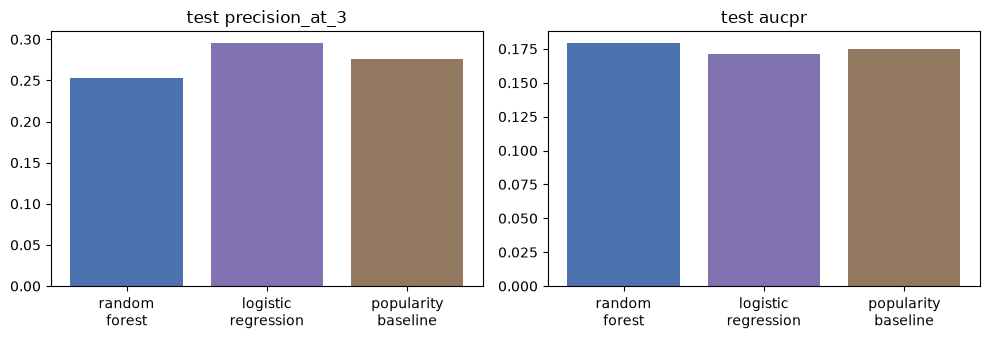

not stored: no threshold reaches 70% precision on validation
stored suggestions: 0


In [14]:
report = json.loads(Path("data/processed/link_prediction_report.json").read_text())
rows = [{"model": name, **{k: round(v, 3) for k, v in splits["test"].items() if k in ("precision_at_3", "recall_at_3", "aucpr")}}
        for name, splits in report["models"].items()]
show(rows)

names = [r["model"].replace("_", "\n") for r in rows]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, metric in zip(axes, ("precision_at_3", "aucpr")):
    ax.bar(names, [r[metric] for r in rows], color=["#4c72b0", "#8172b2", "#937860"])
    ax.set_title(f"test {metric}")
plt.tight_layout()
plt.show()

print(q("MATCH (m:ImportMeta {source: 'predict'}) RETURN m.status AS status")[0]["status"])
print("stored suggestions:", q("MATCH ()-[r:INFERRED_MAPS_TO]->() RETURN count(r) AS n")[0]["n"])

The baseline wins on precision@3, and no threshold reaches the 70% precision target on validation,
so the gate stores nothing. The first trial's 0.75 AUCPR came from a random edge split that leaked
each test CVE's other techniques. Details are in `docs/link_prediction.md`.

## 6. The agent (D19)

The agent answers in plain English. It calls the same functions as above as tools, falls back to
guarded Cypher only when no tool fits, and returns every tool call and citation. The server, not the
LLM, marks each fact verified or model-generated. This cell calls Groq's free tier
(`qwen/qwen3.8-27b`).

In [15]:
from app.agent.graph import Agent
from app.agent.llm import make_chat_model
from app.config import load_settings

settings = load_settings()
agent = Agent(make_chat_model(settings), driver, max_retries=settings.llm_max_retries)
answer = agent.ask("Which three mitigations should we prioritise to cover the techniques behind exploited CVEs?",
                   provider=settings.llm_provider, model_name=settings.llm_model)
print(answer.answer, "\n")
for fact in answer.facts:
    print(f"[{fact.provenance}] {fact.statement}  {fact.citations}")
print()
for call in answer.tool_calls:
    print(f"tool call: {call.tool}({call.arguments}) -> {call.status}; path {call.path}")

LLM rate limited (429), retry 1/6 in 16.3 s


Prioritise these three mitigations (greedy weighted coverage of the 154 techniques reachable from 419 exploited KEV CVEs):

1. M1026 – Privileged Account Management: covers 36 techniques, capturing 42.2% of the total exploited-CVE weight on its own.
2. M1038 – Execution Prevention: adds 15 more techniques, bringing cumulative coverage to 57.1%.
3. M1031 – Network Intrusion Prevention: adds 21 more techniques, bringing cumulative coverage to 66.9%.

Together these three mitigations cover about two-thirds of the exploited-CVE technique weight. Note that ~5.9% of the weight (20 techniques, e.g. T1496 Resource Hijacking, T1202 Indirect Command Execution, T1082 System Information Discovery) has no mapped mitigation and cannot be covered this way. 

[verified] Privileged Account Management (M1026) is the top-ranked mitigation, covering 36 techniques and 42.2% of the exploited-CVE technique weight.  ['M1026']
[verified] Execution Prevention (M1038) is second, adding 15 techniques for a cumula

### A guardrail rejecting bad LLM output

A real model can't be relied on to misbehave on cue, so here the "LLM" is scripted: it first tries to
wipe the graph, then uses a label that does not exist, then sends a correct query. The guardrails,
tools and Neo4j are the real ones. The final answer cites one id a tool returned and one it made up.

In [16]:
from app.agent.scripted import ScriptedChatModel
from scripts.guardrail_demo import QUESTION, SCRIPT
from app.agent.scripted import tool_call

scripted = ScriptedChatModel(replies=[tool_call(name, f"call_{i}", **args) for i, (name, args) in enumerate(SCRIPT)])
demo = Agent(scripted, driver).ask(QUESTION, provider="scripted", model_name="guardrail-demo")
for call in demo.tool_calls:
    print(f"step {call.step}: {call.tool} -> {call.status}")
    print(f"   {call.arguments.get('query', '')}")
    if call.error:
        print(f"   rejected: {call.error}")
    if call.cypher:
        print(f"   ran: {call.cypher!r}")
print()
print(demo.answer)
for fact in demo.facts:
    print(f"[{fact.provenance}] {fact.statement}  {fact.citations}  {fact.note or ''}")

step 1: run_cypher -> rejected
   MATCH (n) DETACH DELETE n RETURN count(n)
   rejected: forbidden_keyword: read-only queries cannot use DELETE, DETACH
step 2: run_cypher -> rejected
   MATCH (c:Vulnerability)-[:HAS_WEAKNESS]->(:CWE {cwe_id: 'CWE-79'}) RETURN count(c) AS n
   rejected: explain_unknown_schema: unknown label: Vulnerability (not in the graph schema)
step 3: run_cypher -> ok
   MATCH (c:CVE)-[:HAS_WEAKNESS]->(:CWE {cwe_id: 'CWE-79'}) RETURN count(DISTINCT c) AS n
   ran: "MATCH (c:CVE)-[:HAS_WEAKNESS]->(:CWE {cwe_id: 'CWE-79'}) RETURN count(DISTINCT c) AS n\nLIMIT 50"

34 KEV CVEs have the weakness CWE-79 (cross-site scripting).
[verified] 34 KEV CVEs have weakness CWE-79  ['CWE-79']  
[model-generated] APT29 exploited these CVEs  ['G0016']  cites ids no tool returned: G0016


The same checks are available without an LLM through `POST /agent/check-cypher`:

In [17]:
from app.agent.guardrails import GuardrailError, check_cypher, explain

for query in ["MATCH (c:CVE) SET c.cvss_score = 0 RETURN count(c)",
              "CALL dbms.security.createUser('eve', 'pw', false)",
              "MATCH (g:Group)-[:EXPLOITS]->(c:CVE) RETURN g, c",
              "MATCH (n:CVE) RETURN n.cve_id LIMIT 100000"]:
    try:
        checked = check_cypher(query)
        explain(driver, checked)
        print(f"allowed:  {checked!r}")
    except GuardrailError as error:
        print(f"REJECTED: {query}\n          {error.rule}: {error.reason}")

REJECTED: MATCH (c:CVE) SET c.cvss_score = 0 RETURN count(c)
          forbidden_keyword: read-only queries cannot use SET
REJECTED: CALL dbms.security.createUser('eve', 'pw', false)
          not_a_read_clause: the query must start with one of MATCH, OPTIONAL MATCH, WITH, UNWIND, RETURN
REJECTED: MATCH (g:Group)-[:EXPLOITS]->(c:CVE) RETURN g, c
          explain_unknown_schema: unknown relationship type: EXPLOITS (not in the graph schema)
allowed:  'MATCH (n:CVE) RETURN n.cve_id LIMIT 50'


On the 15-question evaluation (`make evaluate-agent`), the agent passed 13: both prompt injections
were refused, and the graph was unchanged after every question. The two failures and the known limits
are in D19.

In [18]:
driver.close()